# Bengaluru Urban Heat Island Prediction

## 1. Load and inspect the dataset


In [1]:
import pandas as pd

df = pd.read_csv("ultimate_uhi_dataset_with_rwi.csv")

print("Rows and columns:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).head(10))

Rows and columns: (2433, 27)


,EVI,LST,MNDWI,NDBI,NDVI,NO2_Emissions,Pop_Density,Relative_Humidity,SAVI,Wind_Speed,...,Street_Density,Height_Variability,SVF_Proxy,Air_Temp_C,Albedo,MODIS_LST,Soil_Moisture,Surface_Pressure_hPa,Relative_Wealth_Index,Dist_to_RWI_Node
0,0.892517,36.269642,-0.149811,-0.015697,0.155340,0.000114,13.377932,44.010008,0.233005,1.316945,...,762.803405,0.0,0.556827,25.176014,12519.5162,34.41,0.133605,911.173046,1.466,926.376329
1,0.757597,29.934342,-0.047928,-0.036504,0.082115,0.000111,6.732914,44.010008,0.123170,1.316945,...,1328.787241,0.0,0.789741,25.176014,12258.6017,33.95,0.133605,911.173046,1.466,1175.639506
2,0.362794,34.671717,-0.135709,0.033231,0.081369,0.000111,9.148172,44.010008,0.122052,1.316945,...,663.840788,0.0,0.334735,25.176014,12906.9192,33.57,0.133605,911.173046,1.466,1464.095547
3,1.457438,32.262013,-0.150746,-0.066586,0.228033,0.000110,6.794518,44.010008,0.342043,1.316945,...,1414.341978,0.0,0.298475,25.176014,12137.2512,33.77,0.133605,911.173046,1.561,941.508207
4,0.536430,33.311345,-0.115602,-0.022294,0.115569,0.000110,6.869004,44.010008,0.173351,1.316945,...,1244.431671,0.0,0.259863,25.176014,12584.2982,33.77,0.133605,911.173046,1.561,880.179402


Volume_Density       2064
LST                     0
EVI                     0
NDBI                    0
NDVI                    0
NO2_Emissions           0
Pop_Density             0
Relative_Humidity       0
SAVI                    0
Wind_Speed              0
dtype: int64

## 2. Clean the dataset


In [2]:
df_clean = df.drop(columns=["Volume_Density"])

print("New size:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())

New size: (2433, 26)
Missing values: 0


## 3. Choose the clues, target temperature, and locations


In [3]:
X = df_clean.drop(columns=["LST", "MODIS_LST", "Latitude", "Longitude"])
y = df_clean["LST"]

locations = df_clean[["Latitude", "Longitude"]]

print("Clues for the computer:", X.shape)
print("Temperatures to learn:", y.shape)

Clues for the computer: (2433, 22)
Temperatures to learn: (2433,)


## 4. Split locations into training and test groups


In [4]:
from sklearn.model_selection import GroupShuffleSplit

# Group nearby locations into roughly 1 km areas
area = (
    (locations["Latitude"] * 100).astype(int).astype(str)
    + "_"
    + (locations["Longitude"] * 100).astype(int).astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_index, test_index = next(splitter.split(X, y, groups=area))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]

print("Practice locations:", X_train.shape[0])
print("Quiz locations:", X_test.shape[0])

Practice locations: 1964
Quiz locations: 469


## 5. Train the Linear Regression model


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)

linear_guess = linear_model.predict(X_test)

print("Average error (°C):", mean_absolute_error(y_test, linear_guess))
print("Typical error (°C):", np.sqrt(mean_squared_error(y_test, linear_guess)))
print("Score (closer to 1 is better):", r2_score(y_test, linear_guess))

Average error (°C): 1.310368742735389
Typical error (°C): 1.705207915013638
Score (closer to 1 is better): 0.3304053723510033


## 6. Train the Random Forest model


In [6]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)
forest_guess = forest_model.predict(X_test)

print("Average error (°C):", mean_absolute_error(y_test, forest_guess))
print("Typical error (°C):", np.sqrt(mean_squared_error(y_test, forest_guess)))
print("Score (closer to 1 is better):", r2_score(y_test, forest_guess))

Average error (°C): 1.1528934788205139
Typical error (°C): 1.5240184436743407
Score (closer to 1 is better): 0.4651429476004202


## 7. Install XGBoost


In [7]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 8. Train the XGBoost model


In [8]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_guess = xgb_model.predict(X_test)

print("Average error (°C):", mean_absolute_error(y_test, xgb_guess))
print("Typical error (°C):", np.sqrt(mean_squared_error(y_test, xgb_guess)))
print("Score (closer to 1 is better):", r2_score(y_test, xgb_guess))

Average error (°C): 1.2586796938312173
Typical error (°C): 1.636074841227543
Score (closer to 1 is better): 0.3835986041583789


## 9. Compare the first three models


In [9]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "XGBoost"],
    "MAE": [
        mean_absolute_error(y_test, linear_guess),
        mean_absolute_error(y_test, forest_guess),
        mean_absolute_error(y_test, xgb_guess)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_guess)),
        np.sqrt(mean_squared_error(y_test, forest_guess)),
        np.sqrt(mean_squared_error(y_test, xgb_guess))
    ],
    "R2": [
        r2_score(y_test, linear_guess),
        r2_score(y_test, forest_guess),
        r2_score(y_test, xgb_guess)
    ]
})

display(results.round(3).sort_values("R2", ascending=False))

,Model,MAE,RMSE,R2
1,Random Forest,1.153,1.524,0.465
2,XGBoost,1.259,1.636,0.384
0,Linear Regression,1.310,1.705,0.330


## 10. Train the MLP neural network


In [10]:
from sklearn.neural_network import MLPRegressor

mlp_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=1500,
        early_stopping=True,
        random_state=42
    )
)

mlp_model.fit(X_train, y_train)
mlp_guess = mlp_model.predict(X_test)

print("Average error (°C):", mean_absolute_error(y_test, mlp_guess))
print("Typical error (°C):", np.sqrt(mean_squared_error(y_test, mlp_guess)))
print("Score (closer to 1 is better):", r2_score(y_test, mlp_guess))

Average error (°C): 1.2940502089702337
Typical error (°C): 1.6567299445415307
Score (closer to 1 is better): 0.3679364809259654


## 11. Add MLP results to the comparison


In [11]:
results.loc[len(results)] = [
    "Neural Network (MLP)",
    mean_absolute_error(y_test, mlp_guess),
    np.sqrt(mean_squared_error(y_test, mlp_guess)),
    r2_score(y_test, mlp_guess)
]

display(results.round(3).sort_values("R2", ascending=False))

,Model,MAE,RMSE,R2
1,Random Forest,1.153,1.524,0.465
2,XGBoost,1.259,1.636,0.384
3,Neural Network (MLP),1.294,1.657,0.368
0,Linear Regression,1.310,1.705,0.330


## 12. Find the most useful features


In [12]:
import pandas as pd

importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(importance.head(10))

NDBI                     0.234819
Relative_Wealth_Index    0.182478
NO2_Emissions            0.088544
Dist_Water               0.074841
Pop_Density              0.050608
Dist_Park                0.044922
Dist_to_RWI_Node         0.042626
EVI                      0.036610
Albedo                   0.033032
Dist_Highway             0.030801
dtype: float64

## 13. Compare real and guessed temperatures


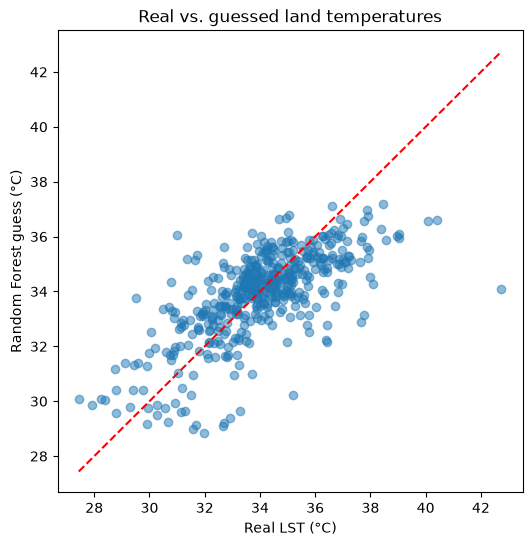

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, forest_guess, alpha=0.5)

plt.xlabel("Real LST (°C)")
plt.ylabel("Random Forest guess (°C)")
plt.title("Real vs. guessed land temperatures")

low = min(y_test.min(), forest_guess.min())
high = max(y_test.max(), forest_guess.max())
plt.plot([low, high], [low, high], "r--")

plt.show()

## 14. Map the guessed temperatures


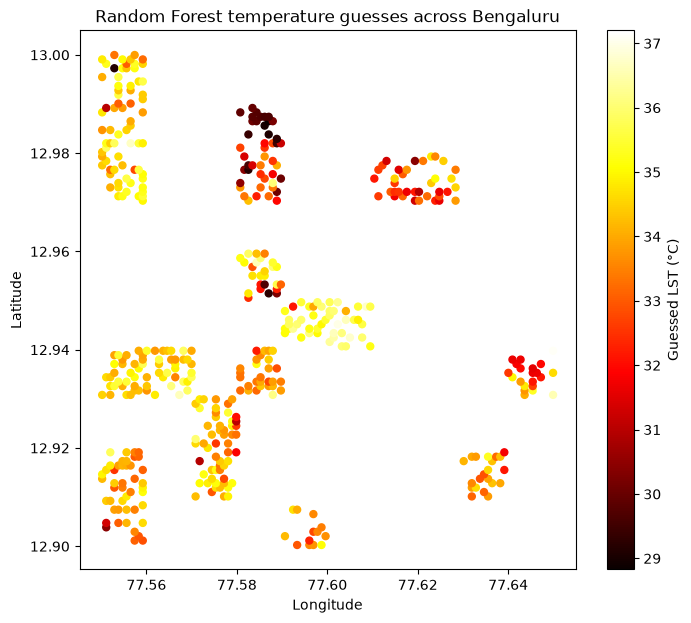

In [14]:
test_locations = locations.iloc[test_index]

plt.figure(figsize=(8, 7))
plt.scatter(
    test_locations["Longitude"],
    test_locations["Latitude"],
    c=forest_guess,
    cmap="hot",
    s=25
)

plt.colorbar(label="Guessed LST (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Random Forest temperature guesses across Bengaluru")
plt.show()

## 15. Group locations by relative heat


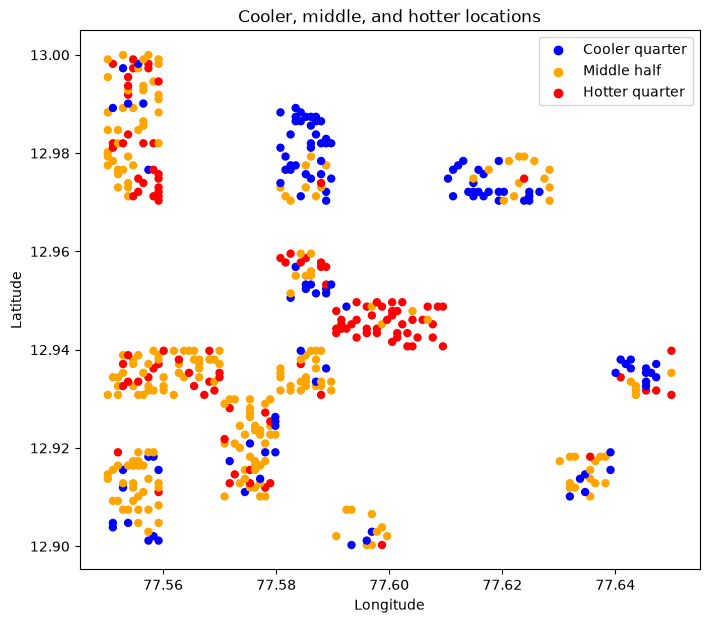

In [15]:
import numpy as np
import matplotlib.pyplot as plt

cool_cutoff = np.percentile(forest_guess, 25)
hot_cutoff = np.percentile(forest_guess, 75)

risk_number = np.where(
    forest_guess <= cool_cutoff, 0,
    np.where(forest_guess >= hot_cutoff, 2, 1)
)

colors = ["blue", "orange", "red"]

plt.figure(figsize=(8, 7))
plt.scatter(
    test_locations["Longitude"],
    test_locations["Latitude"],
    c=[colors[n] for n in risk_number],
    s=25
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Cooler, middle, and hotter locations")
plt.scatter([], [], color="blue", label="Cooler quarter")
plt.scatter([], [], color="orange", label="Middle half")
plt.scatter([], [], color="red", label="Hotter quarter")
plt.legend()
plt.show()

## 16. Install TensorFlow


In [16]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


## 17. Check TensorFlow


In [17]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


## 18. Train the 1D CNN


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# Put the numbers on similar scales
cnn_scaler = StandardScaler()
X_train_scaled = cnn_scaler.fit_transform(X_train)
X_test_scaled = cnn_scaler.transform(X_test)

# A CNN expects each row to have a third dimension
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

# Build the CNN
cnn_model = Sequential([
    Input(shape=(X_train_cnn.shape[1], 1)),
    Conv1D(32, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(1)
])

cnn_model.compile(optimizer="adam", loss="mse")

# Teach it using the training rows
stop_early = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    callbacks=[stop_early],
    verbose=1
)

# Ask it to guess the test temperatures
cnn_guess = cnn_model.predict(X_test_cnn).ravel()

print("Average error (°C):", mean_absolute_error(y_test, cnn_guess))
print("Typical error (°C):", np.sqrt(mean_squared_error(y_test, cnn_guess)))
print("Score (closer to 1 is better):", r2_score(y_test, cnn_guess))

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - loss: 821.3647 - val_loss: 207.8882
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 94.2658 - val_loss: 65.7378
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 36.9148 - val_loss: 52.1442
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 29.5348 - val_loss: 46.6027
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 24.2915 - val_loss: 43.1713
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 20.4622 - val_loss: 40.5737
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 17.5507 - val_loss: 38.8515
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 15.3114 - val_loss: 37.2864
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 13.4690 - val_loss: 35.8223
Epoch 10/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 11.9070 - val_loss: 34.4714
Epoch 11/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 10.5683 - val_loss: 33.2844
Epoch 12/100
53/53 ━━━━━━━━━

## 19. Add CNN results to the final comparison


In [19]:
results.loc[len(results)] = [
    "1D CNN",
    mean_absolute_error(y_test, cnn_guess),
    np.sqrt(mean_squared_error(y_test, cnn_guess)),
    r2_score(y_test, cnn_guess)
]

display(results.round(3).sort_values("R2", ascending=False))

,Model,MAE,RMSE,R2
1,Random Forest,1.153,1.524,0.465
4,1D CNN,1.271,1.584,0.422
2,XGBoost,1.259,1.636,0.384
3,Neural Network (MLP),1.294,1.657,0.368
0,Linear Regression,1.310,1.705,0.330


## Conclusion

I compared five models to estimate land surface temperature in Bengaluru:
Linear Regression, Random Forest, XGBoost, MLP, and a 1D CNN.

Random Forest performed best on the held-out locations. Its R² score was 0.465,
and its average prediction error was about 1.15°C. NDBI, Relative Wealth Index,
and NO₂ emissions were among the features it used most.

The map shows which sampled locations the model estimated to be relatively
hotter or cooler. These labels compare locations in this dataset; they are not
official heat warnings.

## Limitations

The dataset covers only the locations and measurements it contains. Empty map
areas have no sampled points, and the model has not measured every place in
Bengaluru. This project estimates land surface temperature; it does not forecast
air temperature or future weather.